# FEM with Lagrange Polynomials in Natural Coordinates

This notebook solves the same two FEM examples we solved in Lecture #10, but the Lagrange interpolation functions are now defined on the Natural coordinates

$$
-1\leq \xi \leq 1
$$

rather than directly in the physical coordinate $x$. Thus we do not have to deal with functional form of Lagrange

The element geometry is mapped using

$$
x(\xi)=\sum_{a=1}^{n}N_a(\xi)x_a
$$

with Jacobian

$$
\boxed{J=\frac{dx}{d\xi}}.
$$

Therefore,

$$
\boxed{\frac{dN_i}{dx}=\frac{1}{J}\frac{dN_i}{d\xi}}
$$

and

$$
\boxed{dx=J\,d\xi}.
$$




In [ ]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

# Natural coordinate
xi = sp.symbols('xi', real=True)


def lagrange_basis(xi, natural_nodes, i):
    # Return the i-th Lagrange interpolation function in xi.
    N = 1
    for j in range(len(natural_nodes)):
        if j != i:
            N *= (xi-natural_nodes[j])/(natural_nodes[i]-natural_nodes[j])
    return sp.simplify(N)


def coordinate_mapping(N, physical_nodes):
    # Return x(xi) and J = dx/dxi for an element.
    x_map = 0
    for a in range(len(N)):
        x_map += N[a]*physical_nodes[a]
    x_map = sp.simplify(x_map)
    J = sp.simplify(sp.diff(x_map, xi))
    return x_map, J


# Parent-element nodal locations
linear_nat_nodes = [sp.Integer(-1), sp.Integer(1)]
cubic_nat_nodes = [
    sp.Integer(-1),
    -sp.Rational(1,3),
    sp.Rational(1,3),
    sp.Integer(1)
]

# Lagrange interpolation functions in natural coordinates
N_linear = [lagrange_basis(xi, linear_nat_nodes, i) for i in range(2)]
N_cubic = [lagrange_basis(xi, cubic_nat_nodes, i) for i in range(4)]

print('Linear Lagrange functions:')
for i, Ni in enumerate(N_linear):
    print(f'N{i+1}(xi) = {sp.factor(Ni)}')

print('\nCubic Lagrange functions:')
for i, Ni in enumerate(N_cubic):
    print(f'N{i+1}(xi) = {sp.factor(Ni)}')


Linear Lagrange functions:
N1(xi) = -(xi - 1)/2
N2(xi) = (xi + 1)/2

Cubic Lagrange functions:
N1(xi) = -(xi - 1)*(3*xi - 1)*(3*xi + 1)/16
N2(xi) = 9*(xi - 1)*(xi + 1)*(3*xi - 1)/16
N3(xi) = -9*(xi - 1)*(xi + 1)*(3*xi + 1)/16
N4(xi) = (xi + 1)*(3*xi - 1)*(3*xi + 1)/16


# Problem 1

$$
-u''=\cos(\pi x),\qquad 0<x<1
$$

with

$$
u(0)=u(1)=0.
$$

The weak form is

$$
\int_0^1 u'v'\,dx
=
\int_0^1 \cos(\pi x)v\,dx.
$$

For an element mapped to $-1\leq\xi\leq1$,

$$
x(\xi)=\sum_a N_a(\xi)x_a,
\qquad
J=\frac{dx}{d\xi}.
$$

Using

$$
\frac{dN_i}{dx}
=
\frac{1}{J}\frac{dN_i}{d\xi},
\qquad
dx=J\,d\xi,
$$

the element equations become

$$
\boxed{
K_{ij}^e
=
\int_{-1}^{1}
\frac{dN_i}{d\xi}
\frac{dN_j}{d\xi}
\frac{1}{J}\,d\xi
}
$$

and

$$
\boxed{
F_i^e
=
\int_{-1}^{1}
N_i(\xi)\cos\!\left(\pi x(\xi)\right)J\,d\xi
}.
$$


## Three 2-node linear elements

For three linear elements,

$$
N_e=3,\qquad n=2,
$$

so the number of global nodes is

$$
N_e(n-1)+1=3(2-1)+1=4.
$$

The physical nodes are

$$
x=\left[0,\frac13,\frac23,1\right].
$$

Every element uses the same natural-coordinate shape functions on $[-1,1]$; only $x^e(\xi)$ and $J^e$ change.


In [ ]:
# -----------------------------
# Three linear elements in natural coordinates
# -----------------------------

nodes = [
    sp.Integer(0),
    sp.Rational(1,3),
    sp.Rational(2,3),
    sp.Integer(1)
]

nodes_float = np.array([float(v) for v in nodes])

connectivity = [
    [0, 1],
    [1, 2],
    [2, 3]
]

K_global = np.zeros((4,4))
F_global = np.zeros(4)

for e in range(3):

    dofs = connectivity[e]
    physical_nodes = [nodes[dofs[0]], nodes[dofs[1]]]

    # Isoparametric mapping x(xi) and Jacobian
    x_map, J = coordinate_mapping(N_linear, physical_nodes)

    print('\nElement', e+1)
    print('x(xi) =', x_map)
    print('J = dx/dxi =', J)

    Ke = np.zeros((2,2))
    Fe = np.zeros(2)

    for i in range(2):

        dNi_dxi = sp.diff(N_linear[i], xi)

        for j in range(2):

            dNj_dxi = sp.diff(N_linear[j], xi)

            Ke[i,j] = float(
                sp.integrate(
                    dNi_dxi*dNj_dxi/J,
                    (xi,-1,1)
                )
            )

        Fe[i] = float(
            sp.integrate(
                N_linear[i]
                * sp.cos(sp.pi*x_map)
                * J,
                (xi,-1,1)
            )
        )

    print('Ke =')
    print(Ke)
    print('Fe =')
    print(Fe)

    # Assembly
    for i in range(2):
        I = dofs[i]
        F_global[I] += Fe[i]

        for j in range(2):
            Jg = dofs[j]
            K_global[I,Jg] += Ke[i,j]

print('\nFinal global K:')
print(K_global)

print('\nFinal global F:')
print(F_global)



Element 1
x(xi) = xi/6 + 1/6
J = dx/dxi = 1/6


Ke =
[[ 3. -3.]
 [-3.  3.]]
Fe =
[0.15198178 0.12368267]

Element 2
x(xi) = xi/6 + 1/2
J = dx/dxi = 1/6


Ke =
[[ 3. -3.]
 [-3.  3.]]
Fe =
[ 0.0282991 -0.0282991]

Element 3
x(xi) = xi/6 + 5/6
J = dx/dxi = 1/6


Ke =
[[ 3. -3.]
 [-3.  3.]]
Fe =
[-0.12368267 -0.15198178]

Final global K:
[[ 3. -3.  0.  0.]
 [-3.  6. -3.  0.]
 [ 0. -3.  6. -3.]
 [ 0.  0. -3.  3.]]

Final global F:
[ 0.15198178  0.15198178 -0.15198178 -0.15198178]


In [ ]:
# -----------------------------
# Apply u1 = 0 and u4 = 0
# directly to the full 4x4 system
# -----------------------------

K_bc = K_global.copy()
F_bc = F_global.copy()

# u1 = 0
K_bc[0,:] = 0.0
K_bc[:,0] = 0.0
K_bc[0,0] = 1.0
F_bc[0] = 0.0

# u4 = 0
K_bc[3,:] = 0.0
K_bc[:,3] = 0.0
K_bc[3,3] = 1.0
F_bc[3] = 0.0

print("Final global K after boundary conditions:")
print(K_bc)

print("\nFinal global F after boundary conditions:")
print(F_bc)

U_linear = np.linalg.solve(K_bc,F_bc)

print("Linear FEM solution:")
for i in range(4):
    print(f"Node {i+1}: x = {nodes_float[i]:.6f}, u = {U_linear[i]:.8f}")


Final global K after boundary conditions:
[[ 1.  0.  0.  0.]
 [ 0.  6. -3.  0.]
 [ 0. -3.  6.  0.]
 [ 0.  0.  0.  1.]]

Final global F after boundary conditions:
[ 0.          0.15198178 -0.15198178  0.        ]
Linear FEM solution:
Node 1: x = 0.000000, u = 0.00000000
Node 2: x = 0.333333, u = 0.01688686
Node 3: x = 0.666667, u = -0.01688686
Node 4: x = 1.000000, u = 0.00000000


In [ ]:
# Reconstruct the piecewise-linear solution using natural coordinates

xi_plot = np.linspace(-1,1,100)

x_linear_plot = []
u_linear_plot = []

for e in range(3):

    dofs = connectivity[e]
    physical_nodes = [nodes[dofs[0]], nodes[dofs[1]]]

    x_map, J = coordinate_mapping(N_linear, physical_nodes)

    x_fun = sp.lambdify(xi, x_map, 'numpy')
    N1_fun = sp.lambdify(xi, N_linear[0], 'numpy')
    N2_fun = sp.lambdify(xi, N_linear[1], 'numpy')

    xe = np.asarray(x_fun(xi_plot), dtype=float)

    ue = (
        N1_fun(xi_plot)*U_linear[dofs[0]]
        + N2_fun(xi_plot)*U_linear[dofs[1]]
    )

    x_linear_plot.extend(xe)
    u_linear_plot.extend(ue)

x_linear_plot = np.array(x_linear_plot)
u_linear_plot = np.array(u_linear_plot)


## One 4-node cubic Lagrange element

Use one cubic parent element with natural nodes

$$
\xi=\left[-1,-\frac13,\frac13,1\right]
$$

and physical nodes

$$
x=\left[0,\frac13,\frac23,1\right].
$$

The same cubic Lagrange functions are used for the field and for the coordinate mapping:

$$
u^e(\xi)=\sum_{i=1}^{4}N_i(\xi)u_i,
$$

$$
x(\xi)=\sum_{i=1}^{4}N_i(\xi)x_i.
$$


In [ ]:
# -----------------------------
# One cubic element in natural coordinates
# -----------------------------

cubic_physical_nodes = nodes.copy()

x_cubic, J_cubic = coordinate_mapping(
    N_cubic,
    cubic_physical_nodes
)

print('Cubic element mapping:')
print('x(xi) =', x_cubic)
print('J = dx/dxi =', J_cubic)

print('\nCubic Lagrange functions:')
for i, Ni in enumerate(N_cubic):
    print(f'N{i+1}(xi) = {sp.factor(Ni)}')

K_cubic = np.zeros((4,4))
F_cubic = np.zeros(4)

for i in range(4):

    dNi_dxi = sp.diff(N_cubic[i], xi)

    for j in range(4):

        dNj_dxi = sp.diff(N_cubic[j], xi)

        K_cubic[i,j] = float(
            sp.integrate(
                dNi_dxi*dNj_dxi/J_cubic,
                (xi,-1,1)
            )
        )

    F_cubic[i] = float(
        sp.integrate(
            N_cubic[i]
            * sp.cos(sp.pi*x_cubic)
            * J_cubic,
            (xi,-1,1)
        )
    )

print('\nCubic element/global K:')
print(K_cubic)

print('\nCubic element/global F:')
print(F_cubic)


Cubic element mapping:
x(xi) = xi/2 + 1/2
J = dx/dxi = 1/2

Cubic Lagrange functions:
N1(xi) = -(xi - 1)*(3*xi - 1)*(3*xi + 1)/16
N2(xi) = 9*(xi - 1)*(xi + 1)*(3*xi - 1)/16
N3(xi) = -9*(xi - 1)*(xi + 1)*(3*xi + 1)/16
N4(xi) = (xi + 1)*(3*xi - 1)*(3*xi + 1)/16



Cubic element/global K:
[[ 3.7   -4.725  1.35  -0.325]
 [-4.725 10.8   -7.425  1.35 ]
 [ 1.35  -7.425 10.8   -4.725]
 [-0.325  1.35  -4.725  3.7  ]]

Cubic element/global F:
[ 0.10422465  0.29525315 -0.29525315 -0.10422465]


In [ ]:
# Apply u1 = 0 and u4 = 0
# to the full cubic 4x4 system

K_bc_cubic = K_cubic.copy()
F_bc_cubic = F_cubic.copy()

K_bc_cubic[0,:] = 0.0
K_bc_cubic[:,0] = 0.0
K_bc_cubic[0,0] = 1.0
F_bc_cubic[0] = 0.0

K_bc_cubic[3,:] = 0.0
K_bc_cubic[:,3] = 0.0
K_bc_cubic[3,3] = 1.0
F_bc_cubic[3] = 0.0

print("Final global K after boundary conditions:")
print(K_bc_cubic)

print("\nFinal global F after boundary conditions:")
print(F_bc_cubic)

U_cubic = np.linalg.solve(K_bc_cubic,F_bc_cubic)

print("Cubic FEM solution:")
for i in range(4):
    print(f"Node {i+1}: x = {nodes_float[i]:.6f}, u = {U_cubic[i]:.8f}")


Final global K after boundary conditions:
[[ 1.     0.     0.     0.   ]
 [ 0.    10.8   -7.425  0.   ]
 [ 0.    -7.425 10.8    0.   ]
 [ 0.     0.     0.     1.   ]]

Final global F after boundary conditions:
[ 0.          0.29525315 -0.29525315  0.        ]
Cubic FEM solution:
Node 1: x = 0.000000, u = 0.00000000
Node 2: x = 0.333333, u = 0.01620045
Node 3: x = 0.666667, u = -0.01620045
Node 4: x = 1.000000, u = 0.00000000


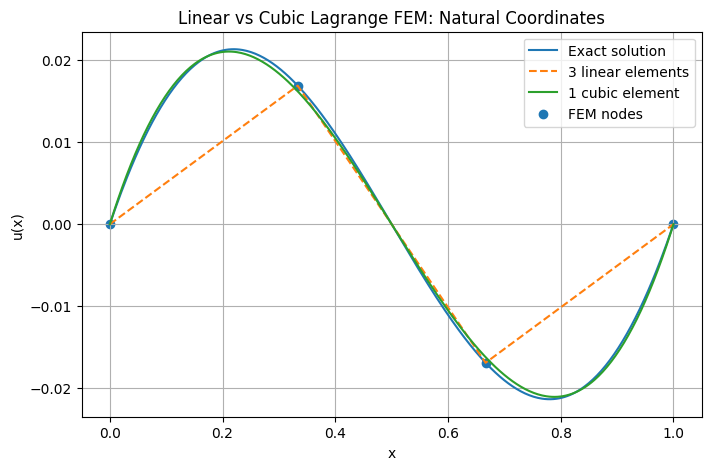

In [ ]:
# Compare linear, cubic, and exact solution

# Cubic solution is reconstructed in xi and mapped to x
xi_cubic_plot = np.linspace(-1,1,400)

x_cubic_fun = sp.lambdify(xi, x_cubic, 'numpy')
x_cubic_plot = np.asarray(x_cubic_fun(xi_cubic_plot), dtype=float)

u_cubic_plot = np.zeros_like(xi_cubic_plot)

for i in range(4):
    Ni_fun = sp.lambdify(xi, N_cubic[i], 'numpy')
    u_cubic_plot += Ni_fun(xi_cubic_plot)*U_cubic[i]


def u_exact(x):
    return (np.cos(np.pi*x) + 2*x - 1)/np.pi**2

x_plot = np.linspace(0,1,400)

plt.figure(figsize=(8,5))
plt.plot(x_plot,u_exact(x_plot),label='Exact solution')
plt.plot(x_linear_plot,u_linear_plot,'--',label='3 linear elements')
plt.plot(x_cubic_plot,u_cubic_plot,label='1 cubic element')
plt.scatter(nodes_float,U_linear,label='FEM nodes')
plt.xlabel('x')
plt.ylabel('u(x)')
plt.title('Linear vs Cubic Lagrange FEM: Natural Coordinates')
plt.grid()
plt.legend()
plt.show()


# Problem 2: 1-D Heat Conduction

Solve

$$
-\frac{d}{dx}\left(kA\frac{dT}{dx}\right)=q'''A
$$

with

$$
L=0.30\ {\rm m},\quad
k=10\ {\rm W/(mK)},\quad
A=0.01\ {\rm m^2},
$$

$$
q'''=10000\ {\rm W/m^3},
\qquad
T(0)=100^\circ{\rm C},
$$

and convection at $x=L$:

$$
-kA\frac{dT}{dx}=hA(T-T_\infty),
$$

where

$$
h=20\ {\rm W/(m^2K)},
\qquad
T_\infty=25^\circ{\rm C}.
$$

After transformation to natural coordinates,

$$
\boxed{
K_{ij}^e
=
\int_{-1}^{1}
kA
\frac{dN_i}{d\xi}
\frac{dN_j}{d\xi}
\frac{1}{J}\,d\xi
}
$$

and

$$
\boxed{
F_i^e
=
\int_{-1}^{1}
q'''A N_iJ\,d\xi
}.
$$

At the convection boundary, which is $\xi=1$ for the last element,

$$
K_{ij}^{\Gamma}=hA N_i(1)N_j(1),
$$

$$
F_i^{\Gamma}=hAT_\infty N_i(1).
$$


In [ ]:
# Physical properties

L = sp.Rational(3,10)
k = sp.Integer(10)
A = sp.Rational(1,100)
q = sp.Integer(10000)
h = sp.Integer(20)
T_inf = sp.Integer(25)
T_left = 100.0

heat_nodes = [
    sp.Integer(0),
    sp.Rational(1,10),
    sp.Rational(1,5),
    sp.Rational(3,10)
]

heat_nodes_float = np.array([float(v) for v in heat_nodes])

heat_connectivity = [
    [0,1],
    [1,2],
    [2,3]
]


In [ ]:
# -----------------------------
# Three linear heat elements in natural coordinates
# Domain contributions only; convection is added in the next cell.
# -----------------------------

K_heat = np.zeros((4,4))
F_heat = np.zeros(4)

for e in range(3):

    dofs = heat_connectivity[e]
    physical_nodes = [heat_nodes[dofs[0]], heat_nodes[dofs[1]]]

    x_map, J = coordinate_mapping(N_linear, physical_nodes)

    print('\nElement', e+1)
    print('x(xi) =', x_map)
    print('J = dx/dxi =', J)

    Ke = np.zeros((2,2))
    Fe = np.zeros(2)

    for i in range(2):

        dNi_dxi = sp.diff(N_linear[i], xi)

        for j in range(2):

            dNj_dxi = sp.diff(N_linear[j], xi)

            Ke[i,j] = float(
                sp.integrate(
                    k*A*dNi_dxi*dNj_dxi/J,
                    (xi,-1,1)
                )
            )

        Fe[i] = float(
            sp.integrate(
                q*A*N_linear[i]*J,
                (xi,-1,1)
            )
        )

    print('Ke =')
    print(Ke)
    print('Fe =')
    print(Fe)

    for i in range(2):
        I = dofs[i]
        F_heat[I] += Fe[i]

        for j in range(2):
            Jg = dofs[j]
            K_heat[I,Jg] += Ke[i,j]

print('\nGlobal heat K before convection:')
print(K_heat)

print('\nGlobal heat F before convection:')
print(F_heat)



Element 1
x(xi) = xi/20 + 1/20
J = dx/dxi = 1/20
Ke =
[[ 1. -1.]
 [-1.  1.]]
Fe =
[5. 5.]

Element 2
x(xi) = xi/20 + 3/20
J = dx/dxi = 1/20
Ke =
[[ 1. -1.]
 [-1.  1.]]
Fe =
[5. 5.]

Element 3
x(xi) = xi/20 + 1/4
J = dx/dxi = 1/20
Ke =
[[ 1. -1.]
 [-1.  1.]]
Fe =
[5. 5.]

Global heat K before convection:
[[ 1. -1.  0.  0.]
 [-1.  2. -1.  0.]
 [ 0. -1.  2. -1.]
 [ 0.  0. -1.  1.]]

Global heat F before convection:
[ 5. 10. 10.  5.]


In [ ]:
# Add convection at x = L.
# For the final linear element, x=L corresponds to xi=+1.

N_right = np.array([
    float(N_linear[i].subs(xi,1))
    for i in range(2)
])

print('Linear shape functions at xi=+1:')
print(N_right)

# Final element global DOFs are [2,3]
right_dofs = heat_connectivity[-1]

for i in range(2):
    I = right_dofs[i]

    F_heat[I] += float(h*A*T_inf)*N_right[i]

    for j in range(2):
        Jg = right_dofs[j]
        K_heat[I,Jg] += float(h*A)*N_right[i]*N_right[j]

print('Global heat K after convection:')
print(K_heat)

print('\nGlobal heat F after convection:')
print(F_heat)


Linear shape functions at xi=+1:
[0. 1.]
Global heat K after convection:
[[ 1.  -1.   0.   0. ]
 [-1.   2.  -1.   0. ]
 [ 0.  -1.   2.  -1. ]
 [ 0.   0.  -1.   1.2]]

Global heat F after convection:
[ 5. 10. 10. 10.]


In [ ]:
# -----------------------------
# Apply T1 = 100 C
# to the full 4x4 system
# -----------------------------

K_heat_bc = K_heat.copy()
F_heat_bc = F_heat.copy()

# Move known T1 contribution to RHS
F_heat_bc = F_heat_bc - K_heat_bc[:,0]*T_left

# Replace first equation by T1 = 100
K_heat_bc[0,:] = 0.0
K_heat_bc[:,0] = 0.0
K_heat_bc[0,0] = 1.0
F_heat_bc[0] = T_left


print("Final global K after boundary conditions:")
print(K_heat_bc)

print("\nFinal global F after boundary conditions:")
print(F_heat_bc)

T_linear = np.linalg.solve(K_heat_bc,F_heat_bc)

print("Linear FEM temperatures:")
for i in range(4):
    print(
        f"Node {i+1}: "
        f"x = {heat_nodes_float[i]:.2f} m, "
        f"T = {T_linear[i]:.4f} C"
    )


Final global K after boundary conditions:
[[ 1.   0.   0.   0. ]
 [ 0.   2.  -1.   0. ]
 [ 0.  -1.   2.  -1. ]
 [ 0.   0.  -1.   1.2]]

Final global F after boundary conditions:
[100. 110.  10.  10.]
Linear FEM temperatures:
Node 1: x = 0.00 m, T = 100.0000 C
Node 2: x = 0.10 m, T = 110.0000 C
Node 3: x = 0.20 m, T = 110.0000 C
Node 4: x = 0.30 m, T = 100.0000 C


In [ ]:
# Reconstruct piecewise-linear temperature field using xi

xi_plot = np.linspace(-1,1,100)

x_heat_linear = []
T_heat_linear = []

for e in range(3):

    dofs = heat_connectivity[e]
    physical_nodes = [heat_nodes[dofs[0]], heat_nodes[dofs[1]]]

    x_map, J = coordinate_mapping(N_linear, physical_nodes)

    x_fun = sp.lambdify(xi, x_map, 'numpy')
    N1_fun = sp.lambdify(xi, N_linear[0], 'numpy')
    N2_fun = sp.lambdify(xi, N_linear[1], 'numpy')

    xe = np.asarray(x_fun(xi_plot), dtype=float)

    Te = (
        N1_fun(xi_plot)*T_linear[dofs[0]]
        + N2_fun(xi_plot)*T_linear[dofs[1]]
    )

    x_heat_linear.extend(xe)
    T_heat_linear.extend(Te)

x_heat_linear = np.array(x_heat_linear)
T_heat_linear = np.array(T_heat_linear)


## One 4-node cubic heat-conduction element

Use the same four physical points

$$
x=\left[0,0.10,0.20,0.30\right]\ {\rm m}
$$

with natural interpolation nodes

$$
\xi=\left[-1,-\frac13,\frac13,1\right].
$$

The geometry is again obtained from

$$
x(\xi)=\sum_{i=1}^{4}N_i(\xi)x_i,
$$

and the Jacobian follows from $J=dx/d\xi$.


In [ ]:
# One cubic heat-conduction element: domain contributions

x_heat_cubic, J_heat_cubic = coordinate_mapping(
    N_cubic,
    heat_nodes
)

print('Cubic heat mapping:')
print('x(xi) =', x_heat_cubic)
print('J = dx/dxi =', J_heat_cubic)

K_heat_cubic = np.zeros((4,4))
F_heat_cubic = np.zeros(4)

for i in range(4):

    dNi_dxi = sp.diff(N_cubic[i], xi)

    for j in range(4):

        dNj_dxi = sp.diff(N_cubic[j], xi)

        K_heat_cubic[i,j] = float(
            sp.integrate(
                k*A*dNi_dxi*dNj_dxi/J_heat_cubic,
                (xi,-1,1)
            )
        )

    F_heat_cubic[i] = float(
        sp.integrate(
            q*A*N_cubic[i]*J_heat_cubic,
            (xi,-1,1)
        )
    )

print('\nCubic heat element/global K before convection:')
print(K_heat_cubic)

print('\nCubic heat element/global F before convection:')
print(F_heat_cubic)


Cubic heat mapping:
x(xi) = 3*xi/20 + 3/20
J = dx/dxi = 3/20

Cubic heat element/global K before convection:
[[ 1.23333333 -1.575       0.45       -0.10833333]
 [-1.575       3.6        -2.475       0.45      ]
 [ 0.45       -2.475       3.6        -1.575     ]
 [-0.10833333  0.45       -1.575       1.23333333]]

Cubic heat element/global F before convection:
[ 3.75 11.25 11.25  3.75]


In [ ]:
# Add convection at xi = +1

N_right_cubic = np.array([
    float(N_cubic[i].subs(xi,1))
    for i in range(4)
])

print('Cubic shape functions at xi=+1:')
print(N_right_cubic)

for i in range(4):

    F_heat_cubic[i] += (
        float(h*A*T_inf)
        * N_right_cubic[i]
    )

    for j in range(4):

        K_heat_cubic[i,j] += (
            float(h*A)
            * N_right_cubic[i]
            * N_right_cubic[j]
        )

# Apply T1 = 100 C
K_heat_cubic_bc = K_heat_cubic.copy()
F_heat_cubic_bc = F_heat_cubic.copy()

F_heat_cubic_bc = (
    F_heat_cubic_bc
    - K_heat_cubic_bc[:,0]*T_left
)

K_heat_cubic_bc[0,:] = 0.0
K_heat_cubic_bc[:,0] = 0.0
K_heat_cubic_bc[0,0] = 1.0
F_heat_cubic_bc[0] = T_left

T_cubic = np.linalg.solve(
    K_heat_cubic_bc,
    F_heat_cubic_bc
)

print('Cubic FEM temperatures:')
for i in range(4):
    print(
        f'Node {i+1}: '
        f'x = {heat_nodes_float[i]:.2f} m, '
        f'T = {T_cubic[i]:.4f} C'
    )


Cubic shape functions at xi=+1:
[0. 0. 0. 1.]
Cubic FEM temperatures:
Node 1: x = 0.00 m, T = 100.0000 C
Node 2: x = 0.10 m, T = 110.0000 C
Node 3: x = 0.20 m, T = 110.0000 C
Node 4: x = 0.30 m, T = 100.0000 C


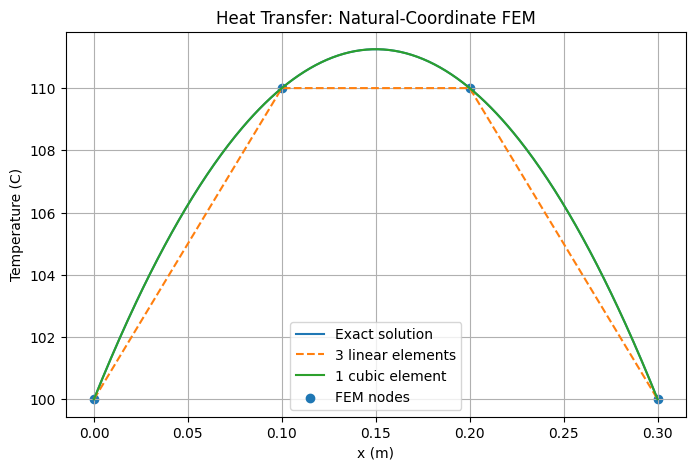

In [ ]:
# Compare linear, cubic, and exact temperature distributions

xi_heat_plot = np.linspace(-1,1,400)

x_heat_cubic_fun = sp.lambdify(
    xi,
    x_heat_cubic,
    'numpy'
)

x_heat_cubic_plot = np.asarray(
    x_heat_cubic_fun(xi_heat_plot),
    dtype=float
)

T_cubic_plot = np.zeros_like(xi_heat_plot)

for i in range(4):

    Ni_fun = sp.lambdify(
        xi,
        N_cubic[i],
        'numpy'
    )

    T_cubic_plot += (
        Ni_fun(xi_heat_plot)
        * T_cubic[i]
    )


def T_exact(x):
    return -500.0*x**2 + 150.0*x + 100.0

x_heat_plot = np.linspace(0,float(L),400)

plt.figure(figsize=(8,5))

plt.plot(
    x_heat_plot,
    T_exact(x_heat_plot),
    label='Exact solution'
)

plt.plot(
    x_heat_linear,
    T_heat_linear,
    '--',
    label='3 linear elements'
)

plt.plot(
    x_heat_cubic_plot,
    T_cubic_plot,
    label='1 cubic element'
)

plt.scatter(
    heat_nodes_float,
    T_linear,
    label='FEM nodes'
)

plt.xlabel('x (m)')
plt.ylabel('Temperature (C)')
plt.title('Heat Transfer: Natural-Coordinate FEM')
plt.grid()
plt.legend()
plt.show()
